# Classify synthetic breast masses with local Kumo Tabular

Use the direct Kumo Tabular API in a local Python notebook to classify generated measurements into simulated `benign` and `malignant` labels.
CPU is the default; this synthetic example demonstrates the API and does not establish clinical performance.
See the [KumoTabular API](https://nvidia.github.io/structured-data-models/api/generated/sdm.models.KumoTabular.html) for context fitting and prediction.

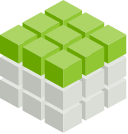

## Install

Use a Python 3.11 or newer notebook kernel with internet access to install the package and download pretrained weights.


In [ ]:
%pip install structured-data-models pandas scikit-learn


## Set the example parameters

Choose the data seed, context size, model size, and number of estimators. Eight estimators combine predictions from different preprocessing configurations; reduce this number to use less compute.
Each run retains generated data and predictions in its own local directory. Set `device` to `cuda` only when a GPU is available.


In [ ]:
from pathlib import Path
from tempfile import mkdtemp
import numpy as np
import pandas as pd
from IPython.display import display
import sdm
import torch

RANDOM_SEED = 42
ROW_COUNT = 20000
CONTEXT_ROWS = 4000
config = {"size": "small", "num_estimators": 8}
device = torch.device("cpu")
CPU_THREADS = 4
OUTPUT_PARENT = Path.cwd()

torch.set_num_threads(CPU_THREADS)
run_dir = Path(mkdtemp(prefix="breast_classification-", dir=OUTPUT_PARENT))
print("Retained run:", run_dir)


## Generate synthetic example data

Run the next cell to create four measurement columns with noisy feature-dependent labels. `Age`, `Shape`, `Margin`, and `Density` are invented, and the label formula is only a demonstration.
You can skim the generator; labeled-context preparation starts below.


In [ ]:
def breast_mass(seed, count):
    rng = np.random.default_rng(seed)
    n = count
    frame = pd.DataFrame({"Age": rng.uniform(20, 90, n).round(3), "Shape": rng.integers(1, 5, n), "Margin": rng.integers(1, 6, n), "Density": rng.uniform(1, 4, n).round(4)})
    risk = (frame.Age - 55) / 20 + (frame.Shape - 2.5) * 0.7 + (frame.Margin - 3) * 0.5
    frame["Severity"] = (rng.random(n) < 1 / (1 + np.exp(-risk))).astype(int)
    return frame

data = breast_mass(RANDOM_SEED, ROW_COUNT)
data_dir = run_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)
data.to_csv(data_dir / "breast_mass.csv", index=False)

print("Generated data:", data_dir)
display(data.head())


## Prepare labeled context

Stratify the split so every class appears in the labeled context and held-out scoring population. The held-out labels remain available only for evaluation.


In [ ]:
from sklearn.model_selection import train_test_split
X = data[["Age", "Shape", "Margin", "Density"]]
y = data["Severity"].map({0: "benign", 1: "malignant"})
classes = sorted(y.unique())
df = X.assign(target=pd.Categorical(y, categories=classes))
train, test = train_test_split(data.index, train_size=CONTEXT_ROWS, stratify=y, random_state=RANDOM_SEED)

assert set(train).isdisjoint(test)
print("Context rows:", len(train), "Held-out scoring rows:", len(test))


## Fit labeled context

Load pretrained weights and cache the labeled context for repeated prediction; this does not train a new task-specific model.


In [ ]:
model = sdm.models.KumoTabular(
    task="classification",
    size=config["size"],
    device=device,
)
table = sdm.TableTensor.from_pandas(
    df=df, stypes={"Age": "numerical", "Density": "numerical",
                   "Shape": "categorical", "Margin": "categorical",
                   "target": "categorical"},
    device=device,
)
with torch.inference_mode():
    model.fit(
        x=table[train].drop_columns("target"), y=table[train, "target"],
        num_estimators=config["num_estimators"],
        generator=torch.Generator(device).manual_seed(RANDOM_SEED),
    )


## Batch predictions

Prepare all held-out features without their target column. The direct API returns predictions in input row order.


In [ ]:
x_score = table[test].drop_columns("target")
assert x_score.size(0) == len(test)


Predict the prepared batch using the fitted context.


In [ ]:
with torch.inference_mode():
    output = model.predict(x_score)


### Inspect and save predictions

Expect one result per input row. `row_id` identifies the generated row, `prediction` is the highest-probability class, and each `probability_<class>` column gives that class's probability.
Check class alignment and probability totals, then save the full batch.


In [ ]:
columns = output.columns[sdm.Stype.numerical]

probabilities = output.numerical[:, [columns.index(c) for c in classes]].cpu().numpy()
predictions = np.array(classes)[probabilities.argmax(axis=1)]

assert len(test) >= 2 and probabilities.shape == (len(test), len(classes))
assert np.isfinite(probabilities).all()
np.testing.assert_allclose(probabilities.sum(axis=1), 1, atol=1e-5)
batch_results = pd.DataFrame({"row_id": test, "prediction": predictions})
assert batch_results.row_id.tolist() == list(test)
for label, values in zip(classes, probabilities.T):
    batch_results[f"probability_{label}"] = values
print(batch_results.head(8).to_string(index=False))
output_path = run_dir / "predictions.csv"
batch_results.to_csv(output_path, index=False)
print("Saved:", output_path)


## Evaluate predictions

**Synthetic-data metrics — demonstration only.** Accuracy is the fraction of held-out rows assigned the correct generated class. ROC AUC measures how well the model ranks rows labeled `malignant` above rows labeled `benign`.
Compare both with a baseline that always selects the most frequent context class; higher scores are better for these metrics.


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

baseline = DummyClassifier(strategy="most_frequent").fit(X.iloc[train], y.iloc[train])
pd.DataFrame({
    "Model": [f'KumoTabular {config["size"]}', "Majority class"],
    "Accuracy": [
        accuracy_score(y.iloc[test], predictions),
        accuracy_score(y.iloc[test], baseline.predict(X.iloc[test])),
    ],
    "ROC AUC": [
        roc_auc_score(y.iloc[test], probabilities[:, classes.index("malignant")]),
        roc_auc_score(y.iloc[test], baseline.predict_proba(X.iloc[test])[:,
                      list(baseline.classes_).index("malignant")]),
    ],
}).set_index("Model").round(4)


## Continue with Structured Data Models

Keep `run_dir` to retain the generated inputs and prediction CSV. See [in-context learning](https://nvidia.github.io/structured-data-models/icl.html) for context preparation and repeated inference.
